# 01 · PROTEUS BIDS metadata: structure, timing, class balance

**Goal.** Understand the dataset's structure *before* touching any EEG signal:
who was recorded how often, how a trial unfolds in time relative to the window
the official benchmark feeds the model, and how classes are balanced and ordered.

**Data.** Only the BIDS sidecar tables (`*_events.tsv`, `participants.tsv`) of
PROTEUS, NEMAR `nm000290`, release `v1.0.0` (the release the official kit uses).
No EEG is loaded. All logic lives in `src/bids_metadata.py` (unit-tested); this
notebook only calls it and plots.

**Reading guide.** *Fact* = read from the dataset / official kit;
*Assumption* = my inference, to be tested; *Recommendation* = suggested next step.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle

from src.bids_metadata import CLASSES, DATASET_REF, cue_trials, fetch_metadata, load_events

META = ROOT / "data" / "nm000290_meta"
if not (META / "participants.tsv").exists():
    print("fetched", fetch_metadata(META), "metadata files at", DATASET_REF)

events = load_events(META)
trials = cue_trials(events)
print(f"{len(events)} events, {len(trials)} cued trials, release {DATASET_REF}")

14980 events, 2655 cued trials, release v1.0.0


In [2]:
# Plot style: neutral surfaces and ink; the three classes get fixed categorical
# slots 1-3 of the reference palette (identity colors, never reused for rank).
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
CLASS_COLOR = {"mi": "#2a78d6", "sub": "#eb6834", "word": "#1baf7a"}
CLASS_NAME = {"mi": "motor imagery (0)", "sub": "mental subtraction (1)", "word": "word generation (2)"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

## 1 · Recording structure

*Fact (dataset README):* 10 participants, 14 sessions. Each session has two
calibration runs (`Acquisition*`, **sham** feedback) followed by four online runs
(`OnlineRaw*`, **real** feedback), on two interfaces: Graz and BrainHero (BH).
Resting-state baselines (run 0) have no cues and are not shown.

The official score averages balanced accuracy over **subject × session ×
interface cells**, so each row below contributes two cells.

In [3]:
runs = (trials.groupby(["subject", "session", "run", "task", "interface", "mode"])
              .size().rename("n_trials").reset_index())
print(trials.groupby("subject")["session"].nunique().rename("sessions").to_frame().T.to_string())
print("cells (subject x session x interface):", trials.groupby(["subject", "session", "interface"]).ngroups)

subject   P01  P02  P03  P04  P05  P06  P07  P08  P09  P10
sessions    1    1    1    3    1    1    1    1    1    3
cells (subject x session x interface): 28


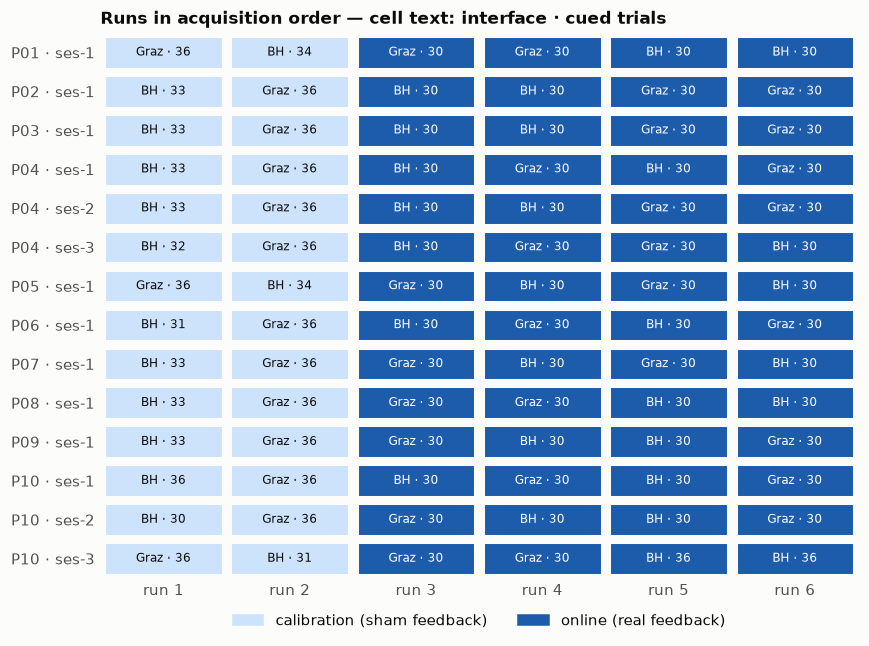

In [4]:
MODE_FILL = {"acquisition": "#cde2fb", "online": "#1c5cab"}
MODE_TEXT = {"acquisition": INK, "online": "#ffffff"}
groups = list(runs.groupby(["subject", "session"]))

fig, ax = plt.subplots(figsize=(8, 0.34 * len(groups) + 1.2))
for i, ((subject, session), g) in enumerate(groups):
    for r in g.itertuples():
        ax.add_patch(Rectangle((r.run - 0.47, i - 0.42), 0.94, 0.84, facecolor=MODE_FILL[r.mode],
                               edgecolor=SURFACE, linewidth=2))
        ax.text(r.run, i, f"{'Graz' if r.interface == 'Graz' else 'BH'} · {r.n_trials}",
                ha="center", va="center", fontsize=8, color=MODE_TEXT[r.mode])
ax.set_xlim(0.5, 6.5); ax.set_ylim(len(groups) - 0.5, -0.5)
ax.set_xticks(range(1, 7), [f"run {k}" for k in range(1, 7)])
ax.set_yticks(range(len(groups)), [f"{s} · ses-{ses}" for (s, ses), _ in groups])
ax.tick_params(length=0); ax.spines[["left", "bottom"]].set_visible(False)
ax.legend(handles=[Patch(color=MODE_FILL["acquisition"], label="calibration (sham feedback)"),
                   Patch(color=MODE_FILL["online"], label="online (real feedback)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=2, frameon=False)
ax.set_title("Runs in acquisition order — cell text: interface · cued trials")
plt.tight_layout(); plt.show()

## 2 · Trial timeline vs. the official model input

*Fact (official kit / NeuralBench config):* the model sees a 4 s window starting
1 s after the cue (`start: 1.0, duration: 4.0`), i.e. cue+1 s → cue+5 s, at 120 Hz
= 480 samples. Below: the trial structure, with pre-cue events taken from one
example trial and post-cue timing measured over **all** trials.

In [5]:
ex = events.query("subject == 'P01' and task == 'OnlineRawGraz' and run == 3").sort_values("onset")
cue0 = ex.loc[ex["trial_type"].isin(CLASSES), "onset"].iloc[0]
pre = {row.trial_type: row.onset - cue0 for row in ex.itertuples() if cue0 - 3 <= row.onset < cue0}
fb, end = trials["feedback_delay"].median(), trials["trial_end"].median()
print("pre-cue events (example trial):", pre)
print(f"feedback start: median {fb:.3f} s after cue; trial end: median {end:.3f} s")

pre-cue events (example trial): {'start_trial': np.float64(-1.5), 'fixation_cross': np.float64(-1.5), 'beep': np.float64(-0.5)}
feedback start: median 3.000 s after cue; trial end: median 8.000 s


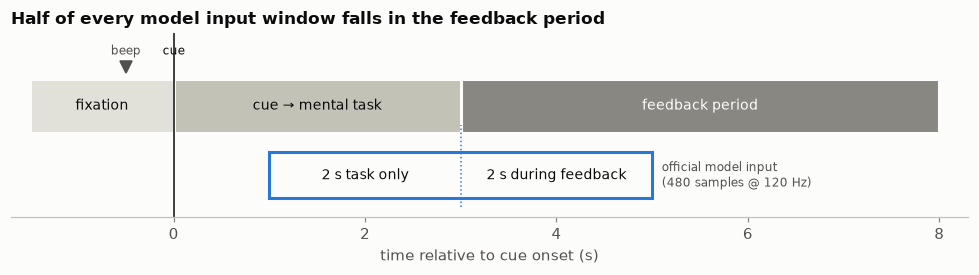

In [6]:
fig, ax = plt.subplots(figsize=(9, 2.6))
phases = [(pre["fixation_cross"], 0, "fixation", "#e1e0d9", INK),
          (0, fb, "cue → mental task", "#c3c2b7", INK),
          (fb, end, "feedback period", "#898781", "#ffffff")]
for x0, x1, label, fill, txt in phases:
    ax.add_patch(Rectangle((x0, 0.55), x1 - x0, 0.35, facecolor=fill, edgecolor=SURFACE, linewidth=2))
    ax.text((x0 + x1) / 2, 0.725, label, ha="center", va="center", fontsize=9, color=txt)
ax.plot([pre["beep"]], [0.98], marker="v", ms=8, color=INK2)
ax.text(pre["beep"], 1.06, "beep", ha="center", fontsize=8, color=INK2)
ax.axvline(0, color=INK, lw=1); ax.text(0, 1.06, "cue", ha="center", fontsize=8)

W0, W1 = 1.0, 5.0
ax.add_patch(Rectangle((W0, 0.12), W1 - W0, 0.3, facecolor="none", edgecolor=CLASS_COLOR["mi"], lw=2))
ax.axvline(fb, ymin=0.05, ymax=0.5, color=CLASS_COLOR["mi"], lw=1, ls=":")
ax.text((W0 + fb) / 2, 0.27, f"{fb - W0:.0f} s task only", ha="center", va="center", fontsize=9)
ax.text((fb + W1) / 2, 0.27, f"{W1 - fb:.0f} s during feedback", ha="center", va="center", fontsize=9)
ax.text(W1 + 0.1, 0.27, "official model input\n(480 samples @ 120 Hz)", va="center", fontsize=8, color=INK2)
ax.set_xlim(pre["fixation_cross"] - 0.2, end + 0.3); ax.set_ylim(0, 1.2)
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xlabel("time relative to cue onset (s)")
ax.set_title("Half of every model input window falls in the feedback period")
plt.tight_layout(); plt.show()

## 3 · Is the timing consistent across trials?

If feedback onset jittered, the task-only / feedback split inside the window
would vary trial to trial. Note the log scale: it makes rare deviations visible.

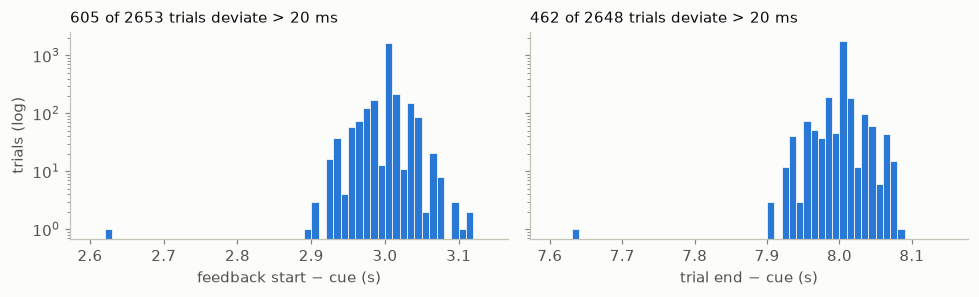

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, col, ref, title in [(axes[0], "feedback_delay", 3.0, "feedback start − cue (s)"),
                            (axes[1], "trial_end", 8.0, "trial end − cue (s)")]:
    v = trials[col].dropna()
    ax.hist(v, bins=np.arange(ref - 0.4, ref + 0.15, 0.01), color=CLASS_COLOR["mi"], edgecolor=SURFACE, lw=0.5)
    ax.set_yscale("log"); ax.set_xlabel(title)
    off = (v - ref).abs() > 0.02
    ax.set_title(f"{off.sum()} of {len(v)} trials deviate > 20 ms", fontweight="normal", fontsize=10)
axes[0].set_ylabel("trials (log)")
plt.tight_layout(); plt.show()

In [8]:
# Where does the jitter come from? Feedback-onset deviation from 3 s, in ms.
jitter = trials.assign(feedback_dev_ms=(trials["feedback_delay"] - 3.0) * 1000)
print("trials with a missing marker:", trials[["feedback_delay", "trial_end"]].isna().any(axis=1).sum())
(jitter.groupby(["interface", "mode"])["feedback_dev_ms"]
       .describe(percentiles=[0.05, 0.5, 0.95]).round(1))

trials with a missing marker: 7


count  mean   std    min    5%  50%   95%    max
interface mode                                                         
BrainHero acquisition  457.0  -0.7  34.0 -374.0 -48.0  0.0  40.0  110.0
          online       852.0  -0.2  31.4 -108.0 -54.3  0.0  48.0  110.0
Graz      acquisition  504.0   0.0   0.0    0.0   0.0  0.0   0.0    0.0
          online       840.0   0.0   0.0    0.0   0.0  0.0   0.0    0.0

## 4 · Class balance per scoring cell

Balanced accuracy is the mean of per-class recall, so it is insensitive to class
imbalance — but each class's recall is estimated from only the trials it has
in that cell. Not a chart: a table answers this better.

In [9]:
cells = trials.pivot_table(index=["subject", "session", "interface"], columns="label",
                           values="onset", aggfunc="count", fill_value=0)[list(CLASSES)]
cells["total"] = cells.sum(axis=1)
print(f"{len(cells)} cells; trials per class per cell: min {cells[list(CLASSES)].min().min()}, "
      f"max {cells[list(CLASSES)].max().max()}; trials per cell: min {cells.total.min()}, max {cells.total.max()}")
cells

28 cells; trials per class per cell: min 29, max 35; trials per cell: min 90, max 103


label                      mi  sub  word  total
subject session interface                      
P01     1       BrainHero  31   32    31     94
                Graz       32   32    32     96
P02     1       BrainHero  32   31    30     93
                Graz       32   32    32     96
P03     1       BrainHero  31   30    32     93
                Graz       32   32    32     96
P04     1       BrainHero  30   31    32     93
                Graz       32   32    32     96
        2       BrainHero  32   30    31     93
                Graz       32   32    32     96
        3       BrainHero  30   31    31     92
                Graz       32   32    32     96
P05     1       BrainHero  31   31    32     94
                Graz       32   32    32     96
P06     1       BrainHero  30   31    30     91
                Graz       32   32    32     96
P07     1       BrainHero  32   31    30     93
                Graz       32   32    32     96
P08     1       BrainHero  31   32    30     93
                Graz       32   32    32     96
P09     1       BrainHero  29   32    32     93
                Graz       32   32    32     96
P10     1       BrainHero  32   32    32     96
                Graz       32   32    32     96
        2       BrainHero  31   30    29     90
                Graz       32   32    32     96
        3       BrainHero  35   34    34    103
                Graz       32   32    32     96

## 5 · Class order within runs

Why it matters: the official evaluation streams windows **in recording order**
and allows label-free adaptation within a session. If classes came in blocks,
any running statistic (e.g. a running mean covariance for re-centering) would be
biased toward the current block, and temporal drift would be confounded with class.

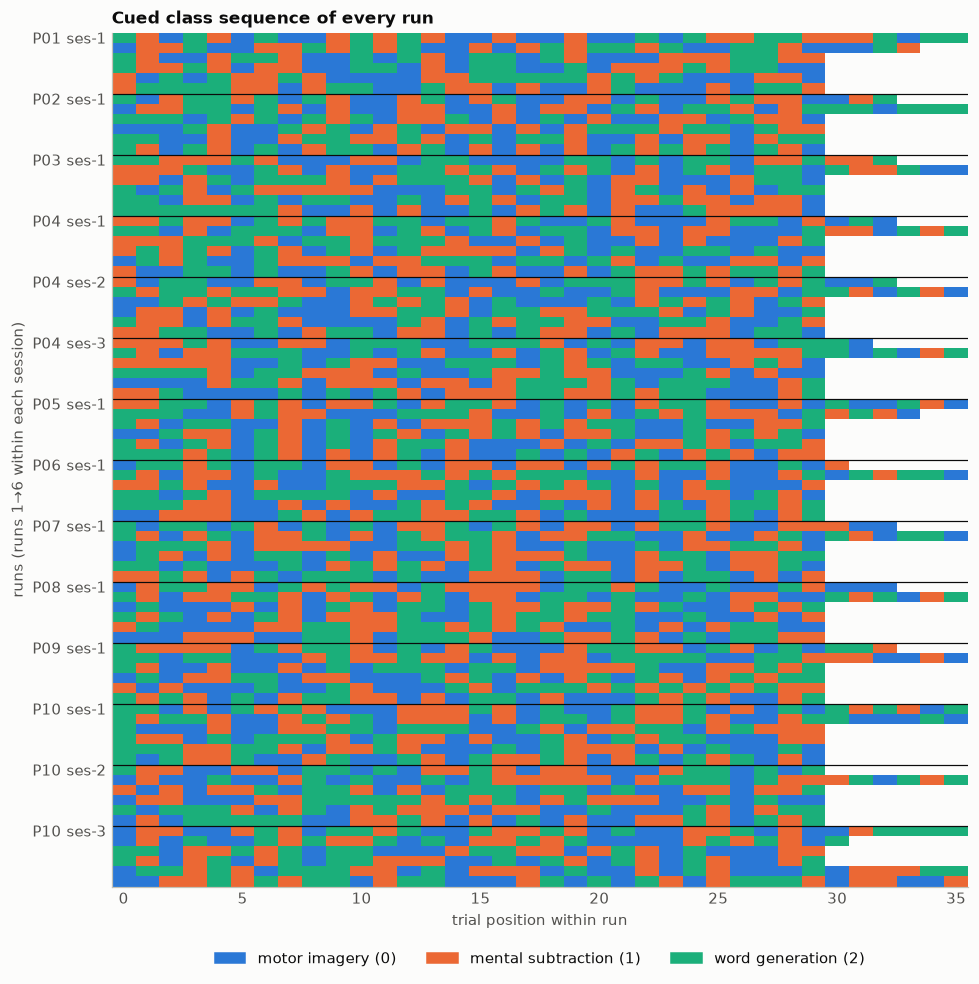

In [10]:
seq = trials.assign(pos=trials.groupby(["subject", "session", "run"]).cumcount())
keys = list(seq.groupby(["subject", "session", "run"]).groups)
code_of = {c: i + 1 for i, c in enumerate(CLASSES)}
mat = np.zeros((len(keys), seq["pos"].max() + 1))
for i, (_, g) in enumerate(seq.groupby(["subject", "session", "run"])):
    mat[i, g["pos"]] = g["label"].map(code_of)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(mat, aspect="auto", interpolation="nearest",
          cmap=ListedColormap([SURFACE] + [CLASS_COLOR[c] for c in CLASSES]), vmin=0, vmax=3)
first = [i for i, k in enumerate(keys) if i == 0 or k[:2] != keys[i - 1][:2]]
ax.set_yticks(first, [f"{keys[i][0]} ses-{keys[i][1]}" for i in first])
for i in first[1:]:
    ax.axhline(i - 0.5, color=INK, lw=0.8)
ax.set_xlabel("trial position within run"); ax.set_ylabel("runs (runs 1→6 within each session)")
ax.tick_params(length=0)
ax.legend(handles=[Patch(color=CLASS_COLOR[c], label=CLASS_NAME[c]) for c in CLASSES],
          loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3, frameon=False)
ax.set_title("Cued class sequence of every run")
plt.tight_layout(); plt.show()

In [11]:
# Quantify: fraction of consecutive trials with the same class, vs. what random
# shuffles of the *same* labels within each run would give (permutation null).
rng = np.random.default_rng(0)
def same_frac(labels):
    labels = np.asarray(labels)
    return np.mean(labels[1:] == labels[:-1])

per_run = [g["label"].to_numpy() for _, g in seq.groupby(["subject", "session", "run"])]
observed = np.mean([same_frac(l) for l in per_run])
null = np.array([np.mean([same_frac(rng.permutation(l)) for l in per_run]) for _ in range(1000)])
p = (np.sum(null <= observed) + 1) / (len(null) + 1)
print(f"same-class repeats: observed {observed:.3f}; shuffled {null.mean():.3f} "
      f"[95% {np.quantile(null, .025):.3f}, {np.quantile(null, .975):.3f}]; one-sided p(fewer repeats) = {p:.3f}")

counts = seq.groupby(["subject", "session", "run", "mode"])["label"].value_counts().unstack(fill_value=0)
print("\nper-run class counts (mi, sub, word) -> number of runs:")
print(counts.groupby("mode").value_counts().rename("runs").to_string())

same-class repeats: observed 0.290; shuffled 0.312 [95% 0.294, 0.330]; one-sided p(fewer repeats) = 0.010

per-run class counts (mi, sub, word) -> number of runs:
mode         mi  sub  word
acquisition  12  12   12      15
                 11   10       2
             11  12   11       1
                 10   12       1
             10  11   12       1
             12  10   11       1
             10  11   11       1
             11  11   12       1
             10  11   10       1
             11  12   10       1
             9   12   12       1
             11  10   9        1
                      10       1
online       10  10   10      54
             12  12   12       2


## Summary

**Facts (computed above, release v1.0.0)**
- 2,655 cued trials in 28 subject × session × interface cells; only **P04 and P10**
  have more than one session (3 each) — the only within-subject view of session drift.
- Every session: 2 calibration runs (sham feedback), then 4 online runs (real
  feedback). The interface order of calibration runs varies across sessions.
- Classes are balanced: 29–35 trials per class per cell (90–103 per cell).
- Feedback starts at cue + 3.0 s — exactly on Graz; on BrainHero with ±~50 ms
  jitter (5th–95th percentile), 7 trials lack a marker. So the official
  window (cue + 1 → 5 s) is **half task-only, half feedback period**.
- Class order is pseudo-random, with slightly *fewer* same-class repeats than
  random shuffling (consistent with a constrained randomization).

**Assumptions to test once the EEG is loaded**
- In online runs the feedback reflects the online classifier's output, which can
  correlate with the true class; a decoder might partly use feedback-evoked
  (e.g. visual) activity rather than the mental task. Test: decode from the
  task-only half (1–3 s) vs. the feedback half (3–5 s), by run mode.
- With ~95 trials per cell, a chance-level classifier's per-cell balanced accuracy
  spreads by several percentage points; the published baselines (32.6–36%) need
  a proper chance distribution before being read as above chance.

**Recommendations**
- Reproduce the official subject split next, and see where P04 / P10 fall.
- Within-session adaptation is reasonable: classes are well mixed in time.